# Predicting March Madness Success
**Cole DiGregorio** · CPSC 4300 Course Project (rebuilt)

March Madness is a spectacle that captures everyone from die-hard college sports fans to casual bracket-fillers.
Many wonder what characteristics in a team lead to resounding March Madness success. Specifically, can we
predict the likelihood of a team making it deep into the tournament based on its offensive and defensive performance?

This notebook rebuilds the original course project, whose files were lost. The original paper is in
[`docs/course_project.md`](docs/course_project.md), and the decisions that had to be inferred are listed in
[`docs/RECONSTRUCTION.md`](docs/RECONSTRUCTION.md). Numbers labeled *Original paper* come from the paper;
every other number is produced by this notebook.

**Contents**
1. Data cleaning
2. K-Means clustering
3. Logistic regression
4. Other things worth noting (champions, Cinderella teams, seeding, and a test on the 2025 tournament)
5. Results and discussion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

plt.rcParams.update({"figure.figsize": (8, 6), "font.size": 11, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Data cleaning
In order to analyze these questions, a large amount of data was needed. The *March Madness Historical Dataset*
by Jonathan Pilafas on Kaggle was used, which compiles KenPom advanced metrics for every NCAA Division I men's
basketball team. Version 31 of the dataset is saved in `data/` so the results can be reproduced.

The two characteristics focused on during this study were adjusted offensive efficiency (points scored per 100
possessions) and adjusted defensive efficiency (points allowed per 100 possessions). Both are adjusted for the
strength of the opponent, which better explains a team's true offensive and defensive efficiency.
These calculations were made by KenPom.

In [2]:
df = pd.read_csv("data/march_madness_kaggle_v31.csv")
print(df.shape)

df = df[["Season", "Mapped ESPN Team Name", "Seed",
         "Adjusted Offensive Efficiency", "Adjusted Offensive Efficiency Rank",
         "Adjusted Defensive Efficiency", "Adjusted Defensive Efficiency Rank",
         "Pre-Tournament.AdjOE", "Pre-Tournament.AdjDE",
         "Post-Season Tournament", "Final Four?", "Tournament Winner?"]]
df = df.rename(columns={"Mapped ESPN Team Name": "Team",
                        "Adjusted Offensive Efficiency": "AdjOE",
                        "Adjusted Offensive Efficiency Rank": "OffRank",
                        "Adjusted Defensive Efficiency": "AdjDE",
                        "Adjusted Defensive Efficiency Rank": "DefRank",
                        "Pre-Tournament.AdjOE": "PreAdjOE",
                        "Pre-Tournament.AdjDE": "PreAdjDE"})
df.head()

(8680, 179)


,Season,Team,Seed,AdjOE,OffRank,AdjDE,DefRank,PreAdjOE,PreAdjDE,Post-Season Tournament,Final Four?,Tournament Winner?
0,2025,Duke,1,130.1,1,90.8,5,127.954,89.7995,March Madness,No,No
1,2026,Duke,1,128.0,4,89.1,2,NaN,NaN,March Madness,No,No
2,2026,Arizona,1,127.7,5,90.0,3,NaN,NaN,March Madness,No,No
3,2026,Michigan,1,126.6,8,89.0,1,NaN,NaN,March Madness,No,No
4,2015,Kentucky,1,121.3,6,84.4,1,121.270,83.8367,March Madness,Yes,No


The study spans 2003 to 2024. There was no tournament in 2020 because of COVID-19. A copy of the full data is
kept in `df_all` so the 2025 tournament can be used as a test later on.

In [3]:
df_all = df.copy()
years = [y for y in range(2003, 2025) if y != 2020]
df = df[df["Season"].isin(years)]
print(len(years), "tournaments,", len(df), "team-seasons (all of Division I)")

21 tournaments, 7271 team-seasons (all of Division I)


Since the dataset includes every Division I team, the next major part of cleaning the data was removing teams
not in the tournament. A list of every tournament team for each year was compiled, and any team not in the
list for its respective year was removed.

In [4]:
tourney_teams = (df[df["Post-Season Tournament"] == "March Madness"]
                 .groupby("Season")["Team"].apply(set).to_dict())

tourney = df[df.apply(lambda row: row["Team"] in tourney_teams[row["Season"]], axis=1)]
tourney = tourney.drop_duplicates(subset=["Season", "Team"]).reset_index(drop=True)
tourney["Seed"] = tourney["Seed"].astype(int)

print(len(tourney), "tournament team-seasons")
print(tourney.groupby("Season").size().to_dict())
print("Missing values:", tourney[["AdjOE", "AdjDE"]].isna().sum().sum())

1402 tournament team-seasons
{2003: 65, 2004: 65, 2005: 65, 2006: 65, 2007: 65, 2008: 65, 2009: 65, 2010: 65, 2011: 68, 2012: 68, 2013: 68, 2014: 68, 2015: 67, 2016: 68, 2017: 68, 2018: 68, 2019: 68, 2021: 68, 2022: 68, 2023: 67, 2024: 68}
Missing values: 0


Similarly, another data frame contains the sets of Elite Eight teams, Final Four teams, and champions for each
year. The Final Four and champions come from the dataset. The Elite Eight is not in the dataset, so it was
compiled by hand in `data/elite_eight.csv` and checked against Sports-Reference brackets.

In [5]:
elite_eight = pd.read_csv("data/elite_eight.csv")

results = pd.DataFrame({
    "Elite Eight": elite_eight.groupby("Season")["Team"].apply(set),
    "Final Four":  tourney[tourney["Final Four?"] == "Yes"].groupby("Season")["Team"].apply(set),
    "Champion":    tourney[tourney["Tournament Winner?"] == "Yes"].groupby("Season")["Team"].apply(set),
})
results.head()

,Elite Eight,Final Four,Champion
Season,,,
2003,"{Arizona, Michigan State, Texas, Syracuse, Okl...","{Texas, Syracuse, Kansas, Marquette}",{Syracuse}
2004,"{Duke, Georgia Tech, Oklahoma State, Xavier, U...","{Oklahoma State, UConn, Duke, Georgia Tech}",{UConn}
2005,"{North Carolina, Arizona, Michigan State, Illi...","{Michigan State, North Carolina, Illinois, Lou...",{North Carolina}
2006,"{Memphis, Florida, Texas, Villanova, UConn, Ge...","{UCLA, Florida, LSU, George Mason}",{Florida}
2007,"{North Carolina, Georgetown, Memphis, Florida,...","{Ohio State, Georgetown, Florida, UCLA}",{Florida}


In [6]:
# 1/0 target columns: did this team reach each round?
rounds = ["Elite Eight", "Final Four", "Champion"]
for col in rounds:
    tourney[col] = tourney.apply(lambda row: int(row["Team"] in results.loc[row["Season"], col]), axis=1)

print(tourney[rounds].sum().to_dict())

# sanity checks: every Final Four team is an Elite Eight team, every champion a Final Four team
assert (tourney["Final Four"] <= tourney["Elite Eight"]).all()
assert (tourney["Champion"] <= tourney["Final Four"]).all()

{'Elite Eight': 168, 'Final Four': 84, 'Champion': 21}


## 2. K-Means clustering
The first method for analyzing the data was K-Means clustering, an unsupervised machine-learning algorithm used
to cluster similar points together. The goal for using K-Means was to separate teams into three distinct groups
based only on offensive and defensive efficiency. The model does not use tournament outcomes to create the
clusters, which allows statistical profiles that correlate to deeper tournament runs to appear naturally.

In [7]:
X = tourney[["AdjOE", "AdjDE"]]
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
raw_labels = kmeans.fit_predict(X)

# K-Means numbers its clusters arbitrarily. Renumber them by net efficiency (AdjOE - AdjDE) of each
# cluster center so the numbering is stable: 0 = weakest, 2 = strongest. Uses only the centers.
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["AdjOE", "AdjDE"])
order = (centers["AdjOE"] - centers["AdjDE"]).sort_values().index
mapping = {old: new for new, old in enumerate(order)}
tourney["Cluster"] = pd.Series(raw_labels).map(mapping)

centers.index = centers.index.map(mapping)
centers = centers.sort_index()
centers["Teams"] = tourney["Cluster"].value_counts().sort_index()
centers.round(1)

,AdjOE,AdjDE,Teams
0,105.0,102.9,339
1,110.8,93.0,568
2,117.3,97.0,495


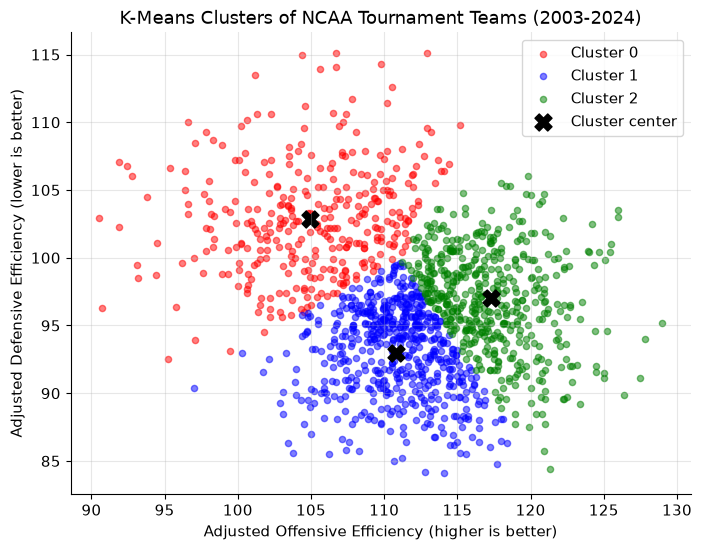

In [8]:
colors = {0: "red", 1: "blue", 2: "green"}

def plot_clusters(alpha):
    for c in [0, 1, 2]:
        group = tourney[tourney["Cluster"] == c]
        plt.scatter(group["AdjOE"], group["AdjDE"], c=colors[c], alpha=alpha, s=20, label=f"Cluster {c}")
    plt.scatter(centers["AdjOE"], centers["AdjDE"], marker="X", c="black", s=150, label="Cluster center")
    plt.xlabel("Adjusted Offensive Efficiency (higher is better)")
    plt.ylabel("Adjusted Defensive Efficiency (lower is better)")

plt.figure()
plot_clusters(alpha=0.5)
plt.title("K-Means Clusters of NCAA Tournament Teams (2003-2024)")
plt.legend()
plt.savefig("figures/figure1_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1**: K-Means clustering of NCAA Division 1 men's tournament teams according to adjusted offensive and
defensive efficiency. Each X marks the center of a cluster.

Elite Eight, Final Four, and championship teams were then overlaid to analyze the relationship between the
clusters and tournament success.

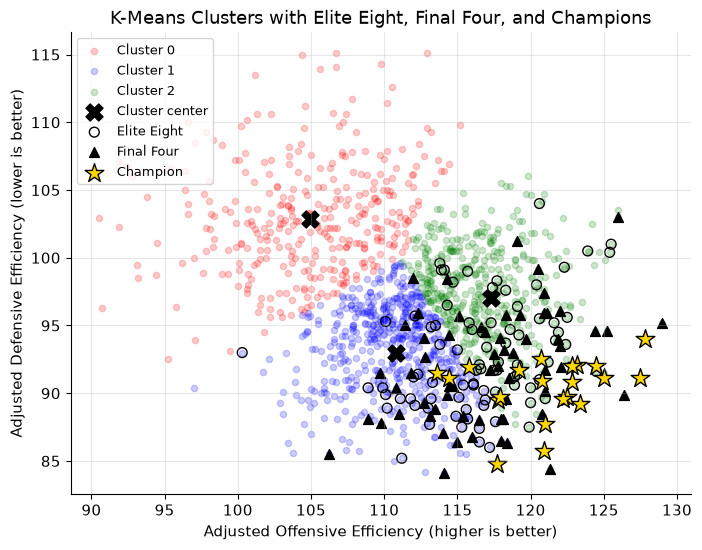

In [9]:
plt.figure()
plot_clusters(alpha=0.2)

e8 = tourney[(tourney["Elite Eight"] == 1) & (tourney["Final Four"] == 0)]
f4 = tourney[(tourney["Final Four"] == 1) & (tourney["Champion"] == 0)]
ch = tourney[tourney["Champion"] == 1]
plt.scatter(e8["AdjOE"], e8["AdjDE"], facecolors="none", edgecolors="black", s=50, label="Elite Eight")
plt.scatter(f4["AdjOE"], f4["AdjDE"], marker="^", c="black", s=50, label="Final Four")
plt.scatter(ch["AdjOE"], ch["AdjDE"], marker="*", c="gold", edgecolors="black", s=200, label="Champion")
plt.title("K-Means Clusters with Elite Eight, Final Four, and Champions")
plt.legend(loc="upper left", fontsize=9)
plt.savefig("figures/figure2_clusters_overlay.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2**: K-Means clustering of NCAA Division 1 men's tournament teams, overlaid with Elite Eight, Final Four,
and championship teams. Visually, a large majority of the successful teams fall inside Cluster 2.

How are the successful teams spread across the clusters? The Elite Eight includes the Final Four and champions,
and the Final Four includes champions.

In [10]:
paper = {"Elite Eight": [0, 40.0, 60.0], "Final Four": [0, 39.8, 60.2], "Champion": [0, 38.1, 61.9]}

rows = []
for col in rounds:
    counts = tourney[tourney[col] == 1]["Cluster"].value_counts().reindex([0, 1, 2], fill_value=0)
    pct = counts / counts.sum() * 100
    for c in [0, 1, 2]:
        rows.append({"Round": col, "Cluster": c, "Teams": counts[c],
                     "Rebuilt %": round(pct[c], 1), "Original paper %": paper[col][c]})
distribution = pd.DataFrame(rows)
distribution

,Round,Cluster,Teams,Rebuilt %,Original paper %
0,Elite Eight,0,0,0.0,0.0
1,Elite Eight,1,68,40.5,40.0
2,Elite Eight,2,100,59.5,60.0
3,Final Four,0,0,0.0,0.0
4,Final Four,1,32,38.1,39.8
5,Final Four,2,52,61.9,60.2
6,Champion,0,0,0.0,0.0
7,Champion,1,4,19.0,38.1
8,Champion,2,17,81.0,61.9


The table above looks at the successful teams. The table below looks at it the other way: out of every team in
a cluster, how many went on to reach each round? This is the more useful view when filling out a bracket.

In [11]:
success_rate = (tourney.groupby("Cluster")[rounds].mean() * 100).round(1)
success_rate.insert(0, "Teams", tourney["Cluster"].value_counts().sort_index())
success_rate.columns = ["Teams", "% reached Elite Eight", "% reached Final Four", "% won title"]
success_rate

,Teams,% reached Elite Eight,% reached Final Four,% won title
Cluster,,,,
0,339,0.0,0.0,0.0
1,568,12.0,5.6,0.7
2,495,20.2,10.5,3.4


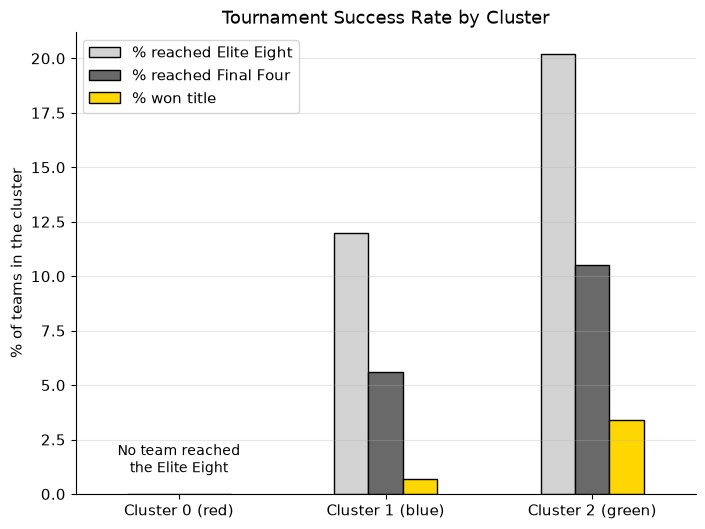

In [12]:
round_colors = ["lightgray", "dimgray", "gold"]

ax = success_rate.drop(columns="Teams").plot(kind="bar", color=round_colors, edgecolor="black", rot=0)
ax.set_xticklabels(["Cluster 0 (red)", "Cluster 1 (blue)", "Cluster 2 (green)"])
ax.set_xlabel("")
ax.set_ylabel("% of teams in the cluster")
ax.set_title("Tournament Success Rate by Cluster")
ax.text(0, 1, "No team reached\nthe Elite Eight", ha="center", fontsize=10)
ax.grid(axis="x", visible=False)
plt.savefig("figures/figure3_success_by_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3**: Percent of teams in each cluster that reached the Elite Eight, reached the Final Four, or won the
championship. A Cluster 2 team was almost twice as likely to reach the Elite Eight as a Cluster 1 team, and about
five times as likely to win the title.

## 3. Logistic regression
The second method used was logistic regression, a supervised learning algorithm for binary classification.
Three separate models were trained: one to predict whether a team makes the Elite Eight, one for the Final Four,
and one for winning the championship. Each model uses the same two features, offensive and defensive efficiency,
and outputs a probability from 0 to 1. Each model is trained on 80% of the tournament teams and evaluated on
the remaining 20%.

In [13]:
X = tourney[["AdjOE", "AdjDE"]]
paper_coefs = {"Elite Eight": (0.2981, -0.3063), "Final Four": (0.2990, -0.3166), "Champion": (0.4557, -0.4046)}

models = {}
coef_rows = []
for target in rounds:
    y = tourney[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    models[target] = model
    y_pred = model.predict(X_test)

    print("=" * 60)
    print(target, "| positives in test set:", y_test.sum(), "of", len(y_test))
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

    coef_rows.append({"Model": target,
                      "AdjOE coef": round(model.coef_[0][0], 4), "AdjDE coef": round(model.coef_[0][1], 4),
                      "Original paper AdjOE": paper_coefs[target][0], "Original paper AdjDE": paper_coefs[target][1]})

coefs = pd.DataFrame(coef_rows)
coefs

Elite Eight | positives in test set: 28 of 281
Accuracy: 0.893
Confusion matrix [[TN FP] [FN TP]]:
[[242  11]
 [ 19   9]]
              precision    recall  f1-score   support

           0       0.93      0.96      0.94       253
           1       0.45      0.32      0.38        28

    accuracy                           0.89       281
   macro avg       0.69      0.64      0.66       281
weighted avg       0.88      0.89      0.89       281

Final Four | positives in test set: 12 of 281
Accuracy: 0.943
Confusion matrix [[TN FP] [FN TP]]:
[[264   5]
 [ 11   1]]
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       269
           1       0.17      0.08      0.11        12

    accuracy                           0.94       281
   macro avg       0.56      0.53      0.54       281
weighted avg       0.93      0.94      0.93       281

Champion | positives in test set: 1 of 281
Accuracy: 0.996
Confusion matrix [[TN FP] [FN TP]]:
[[280   

,Model,AdjOE coef,AdjDE coef,Original paper AdjOE,Original paper AdjDE
0,Elite Eight,0.3076,-0.3327,0.2981,-0.3063
1,Final Four,0.3114,-0.3524,0.2990,-0.3166
2,Champion,0.4444,-0.4079,0.4557,-0.4046


The coefficient represents the change in the log odds of reaching a round for a one-point increase in
efficiency. Converting it to an odds ratio makes it easier to read: the percent change in a team's odds for
each extra point.

In [14]:
odds = coefs[["Model"]].copy()
odds["Odds change per +1 AdjOE"] = ((np.exp(coefs["AdjOE coef"]) - 1) * 100).round(1).astype(str) + "%"
odds["Odds change per +1 AdjDE"] = ((np.exp(coefs["AdjDE coef"]) - 1) * 100).round(1).astype(str) + "%"
odds

,Model,Odds change per +1 AdjOE,Odds change per +1 AdjDE
0,Elite Eight,36.0%,-28.3%
1,Final Four,36.5%,-29.7%
2,Champion,56.0%,-33.5%


**Check (not part of the original project):** the original train/test split is unknown, so this shows how much
the coefficients move across 50 different random splits. This helps judge how far the rebuilt coefficients
could reasonably be from the paper's.

In [15]:
spread = []
for target in rounds:
    for seed in range(50):
        X_train, X_test, y_train, y_test = train_test_split(X, tourney[target], test_size=0.2, random_state=seed)
        m = LogisticRegression(max_iter=1000).fit(X_train, y_train)
        spread.append({"Model": target, "AdjOE coef": m.coef_[0][0], "AdjDE coef": m.coef_[0][1]})
pd.DataFrame(spread).groupby("Model", sort=False).agg(["min", "median", "max"]).round(3)

AdjOE coef               AdjDE coef              
                   min median    max        min median    max
Model                                                        
Elite Eight      0.285  0.307  0.333     -0.333 -0.301 -0.266
Final Four       0.251  0.296  0.336     -0.362 -0.299 -0.264
Champion         0.342  0.461  0.684     -0.604 -0.404 -0.353

### Using the models
`predict_team` takes a team's adjusted offensive and defensive efficiency (from KenPom) and returns its cluster
and the predicted probability of reaching each round. As an example, the 2024 tournament teams are ranked by
predicted chance of winning the title.

In [16]:
def predict_team(adj_oe, adj_de):
    team = pd.DataFrame({"AdjOE": [adj_oe], "AdjDE": [adj_de]})
    result = {"Cluster": int(mapping[kmeans.predict(team)[0]])}
    for target in rounds:
        result["P(" + target + ")"] = round(float(models[target].predict_proba(team)[0, 1]), 3)
    return result

predict_team(120.0, 92.0)

{'Cluster': 2,
 'P(Elite Eight)': 0.605,
 'P(Final Four)': 0.339,
 'P(Champion)': 0.08}

In [17]:
example = tourney[tourney["Season"] == 2024].copy()
for target in rounds:
    example["P(" + target + ")"] = models[target].predict_proba(example[["AdjOE", "AdjDE"]])[:, 1].round(3)
example.sort_values("P(Champion)", ascending=False).head(8)[
    ["Team", "AdjOE", "AdjDE", "Cluster", "Champion", "P(Elite Eight)", "P(Final Four)", "P(Champion)"]]

,Team,AdjOE,AdjDE,Cluster,Champion,P(Elite Eight),P(Final Four),P(Champion)
2,UConn,127.5,91.1,2,1,0.954,0.879,0.779
24,Houston,118.9,87.7,2,0,0.820,0.624,0.236
31,Purdue,125.2,94.6,2,0,0.761,0.509,0.233
65,Auburn,120.4,92.4,2,0,0.602,0.336,0.081
106,Duke,121.6,95.2,2,0,0.463,0.215,0.046
104,Arizona,120.2,93.7,2,0,0.480,0.231,0.045
102,Tennessee,116.8,90.2,1,0,0.510,0.263,0.042
109,North Carolina,119.7,93.5,2,0,0.458,0.216,0.040


## 4. Other things worth noting
These were not part of the original project. They use the same data and the same models to look at a few
questions that came up while rebuilding it.

### 4.1 What did the champions look like?
KenPom also ranks every Division I team (around 350 each year) in offensive and defensive efficiency.

In [18]:
champs = tourney[tourney["Champion"] == 1][["Season", "Team", "Seed", "AdjOE", "OffRank", "AdjDE", "DefRank", "Cluster"]]
champs = champs.sort_values("Season").reset_index(drop=True)
both_top25 = (champs["OffRank"] <= 25) & (champs["DefRank"] <= 25)
print("Champions ranked top 25 in both offense and defense:", both_top25.sum(), "of", len(champs))
print("Champions ranked top 25 in defense:", (champs["DefRank"] <= 25).sum(), "of", len(champs))
champs

Champions ranked top 25 in both offense and defense: 20 of 21
Champions ranked top 25 in defense: 21 of 21


,Season,Team,Seed,AdjOE,OffRank,AdjDE,DefRank,Cluster
0,2003,Syracuse,3,114.4,17,91.1,14,1
1,2004,UConn,2,117.8,9,89.5,6,2
2,2005,North Carolina,1,122.5,2,89.7,5,2
3,2006,Florida,3,117.9,3,89.7,7,2
4,2007,Florida,1,122.8,1,92.0,13,2
5,2008,Kansas,1,120.9,2,85.7,1,2
6,2009,North Carolina,1,123.2,1,92.1,18,2
7,2010,Duke,1,121.0,1,87.7,5,2
8,2011,UConn,3,115.8,19,91.9,15,1
9,2012,Kentucky,1,122.2,2,89.6,7,2


20 of the 21 champions ranked in the top 25 nationally in both offensive and defensive efficiency, and all 21
ranked in the top 25 in defense. The one exception is 2014 UConn, a 7 seed whose offense ranked 39th.
Thus, while a champion does not need the best offense or the best defense, it almost never has a weakness on
either end of the court.

### 4.2 Cinderella teams
Which teams reached the Elite Eight with the weakest numbers? Net efficiency (offensive minus defensive
efficiency) is used as a single measure of team strength.

In [19]:
tourney["Net"] = tourney["AdjOE"] - tourney["AdjDE"]
cinderellas = tourney[tourney["Elite Eight"] == 1].nsmallest(8, "Net")
cinderellas[["Season", "Team", "Seed", "AdjOE", "AdjDE", "Net", "Cluster", "Final Four"]]

,Season,Team,Seed,AdjOE,AdjDE,Net,Cluster,Final Four
1131,2022,Saint Peter's,15,100.3,93.0,7.3,1,0
919,2011,VCU,11,112.0,98.5,13.5,2,1
852,2014,Dayton,11,113.8,99.6,14.2,2,0
801,2018,Kansas State,9,110.1,95.3,14.8,1,0
798,2022,Miami,10,113.9,99.1,14.8,2,0
788,2005,West Virginia,7,114.1,99.1,15.0,2,0
719,2024,NC State,11,114.3,98.4,15.9,2,1
668,2011,Butler,8,112.3,95.9,16.4,1,1


2022 Saint Peter's, a 15 seed, stands out as the weakest Elite Eight team by a wide margin, with a net efficiency
of 7.3 when no other Elite Eight team was below 13. Even so, Saint Peter's falls in Cluster 1, because its defense
was strong. VCU (2011) and NC State (2024) both reached the Final Four as 11 seeds. These teams are what make
March Madness so hard to predict, and no model based only on season-long efficiency would have picked them.

### 4.3 How do the clusters compare to seeding?
Seeds (1 to 16) are assigned by the selection committee, which looks at many of the same statistics.

In [20]:
tourney["Seed Group"] = pd.cut(tourney["Seed"], bins=[0, 4, 8, 12, 16], labels=["1-4", "5-8", "9-12", "13-16"])
pd.crosstab(tourney["Seed Group"], tourney["Cluster"])

Cluster,0,1,2
Seed Group,,,
1-4,1,138,196
5-8,0,183,154
9-12,28,201,130
13-16,310,46,15


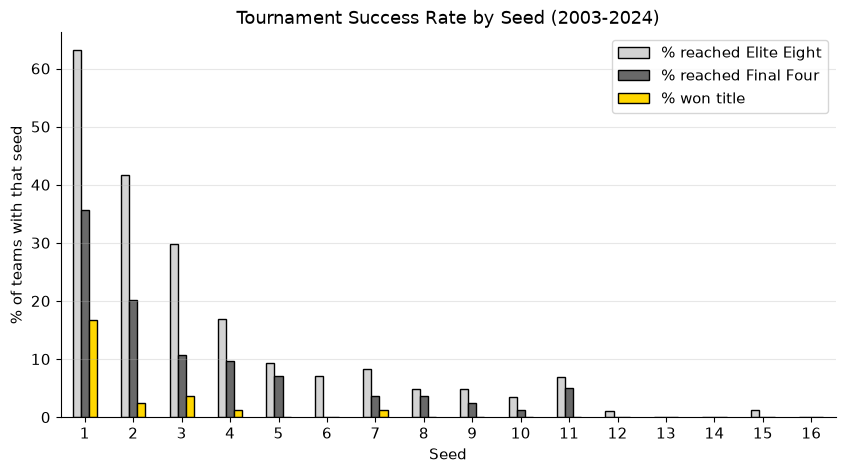

Seed,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
% reached Elite Eight,63.1,41.7,29.8,16.9,9.4,7.1,8.3,4.8,4.8,3.5,6.9,1.1,0.0,0.0,1.2,0.0
% reached Final Four,35.7,20.2,10.7,9.6,7.1,0.0,3.6,3.6,2.4,1.2,5.0,0.0,0.0,0.0,0.0,0.0
% won title,16.7,2.4,3.6,1.2,0.0,0.0,1.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
seed_rate = (tourney.groupby("Seed")[rounds].mean() * 100).round(1)
seed_rate.columns = ["% reached Elite Eight", "% reached Final Four", "% won title"]

ax = seed_rate.plot(kind="bar", color=round_colors, edgecolor="black", rot=0, figsize=(10, 5))
ax.set_xlabel("Seed")
ax.set_ylabel("% of teams with that seed")
ax.set_title("Tournament Success Rate by Seed (2003-2024)")
ax.grid(axis="x", visible=False)
plt.savefig("figures/figure4_success_by_seed.png", dpi=150, bbox_inches="tight")
plt.show()
seed_rate.T

**Figure 4**: Percent of teams with each seed that reached the Elite Eight, reached the Final Four, or won the
championship.

Cluster 0 is mostly made up of 13 to 16 seeds (310 of its 339 teams), which are usually champions of smaller
conferences that earn an automatic bid. This helps explain why no Cluster 0 team reached the Elite Eight, since
these teams also face the strongest opponents in the first rounds. Seeding is also a sharper signal than the
clusters: 1 seeds reached the Elite Eight 63.1% of the time, compared to 20.2% for Cluster 2 teams. This makes
sense because Cluster 2 holds about 24 teams per year, while there are only four 1 seeds.

### 4.4 Testing the models on the 2025 tournament
The models were trained on 2003 to 2024, so the 2025 tournament is a fair test they have never seen. In order to
make the test realistic, the 2025 numbers used are the **pre-tournament** efficiencies, which is what a fan would
actually have when filling out a bracket. The 2025 results were added by hand in `data/results_2025.csv`, since
the dataset does not include them yet. (2026 could not be tested because its pre-tournament numbers are missing.)

In [22]:
t25 = df_all[(df_all["Season"] == 2025) & (df_all["Post-Season Tournament"] == "March Madness")].copy()
t25["Seed"] = t25["Seed"].astype(int)
X_2025 = t25[["PreAdjOE", "PreAdjDE"]].rename(columns={"PreAdjOE": "AdjOE", "PreAdjDE": "AdjDE"})

t25["Cluster"] = [mapping[c] for c in kmeans.predict(X_2025)]
for target in rounds:
    t25["P(" + target + ")"] = models[target].predict_proba(X_2025)[:, 1].round(3)

actual = pd.read_csv("data/results_2025.csv")
actual.columns = ["Team", "Actual Elite Eight", "Actual Final Four", "Actual Champion"]
t25 = t25.merge(actual, on="Team", how="left")
for col in ["Actual Elite Eight", "Actual Final Four", "Actual Champion"]:
    t25[col] = t25[col].fillna(0).astype(int)

top8 = t25.nlargest(8, "P(Elite Eight)")
top4 = t25.nlargest(4, "P(Final Four)")
print("Model's top 8 Elite Eight picks that made the Elite Eight:", int(top8["Actual Elite Eight"].sum()), "of 8")
print("Model's top 4 Final Four picks that made the Final Four:", int(top4["Actual Final Four"].sum()), "of 4")
print("Model's champion pick:", t25.loc[t25["P(Champion)"].idxmax(), "Team"], "| Actual champion: Florida")
print("2025 tournament teams per cluster:", t25["Cluster"].value_counts().sort_index().to_dict())

t25.sort_values("P(Champion)", ascending=False).head(10)[
    ["Team", "Seed", "Cluster", "P(Elite Eight)", "P(Final Four)", "P(Champion)",
     "Actual Elite Eight", "Actual Final Four", "Actual Champion"]]

Model's top 8 Elite Eight picks that made the Elite Eight: 8 of 8
Model's top 4 Final Four picks that made the Final Four: 4 of 4
Model's champion pick: Duke | Actual champion: Florida
2025 tournament teams per cluster: {0: 16, 1: 5, 2: 47}


,Team,Seed,Cluster,P(Elite Eight),P(Final Four),P(Champion),Actual Elite Eight,Actual Final Four,Actual Champion
0,Duke,1,2,0.973,0.930,0.880,1,1,0
2,Florida,1,2,0.949,0.865,0.769,1,1,1
3,Auburn,1,2,0.928,0.813,0.677,1,1,0
1,Houston,1,2,0.944,0.861,0.671,1,1,0
4,Tennessee,2,2,0.813,0.607,0.241,1,0,0
5,Alabama,2,2,0.712,0.437,0.195,1,0,0
8,Texas Tech,3,2,0.577,0.296,0.097,1,0,0
7,Gonzaga,8,2,0.525,0.257,0.069,0,0,0
6,Michigan State,2,2,0.582,0.323,0.064,1,0,0
11,Iowa State,3,2,0.526,0.269,0.054,0,0,0


The eight teams the model gave the highest Elite Eight chances were exactly the eight teams that reached the
Elite Eight, and its top four Final Four picks were exactly the Final Four. The model's top champion pick was Duke,
while the actual champion, Florida, had the second-highest chance. All eight Elite Eight teams fell in Cluster 2.

Interestingly, 47 of the 68 teams in 2025 fell in Cluster 2, compared to about 24 per year before. This is
because offensive efficiency has risen over time: the average tournament team's offensive efficiency was 109.9 in
2003 and 116.2 in 2025. Since the clusters were built from all of the years together, newer teams are more
likely to land in the high-offense cluster.

However, 2025 was an unusually predictable tournament: all four 1 seeds reached the Final Four, so simply picking
the top seeds would have done almost as well. One tournament is not enough to say the models work this well in
general. Also, each model scores every team on its own, so the probabilities do not add up to 100% across the
68 teams. They are best used to rank teams, not as exact chances.

## 5. Results and discussion

In [23]:
# Rebuilt results next to the original paper's
summary = distribution[distribution["Cluster"] > 0].pivot(index="Round", columns="Cluster",
                                                         values=["Rebuilt %", "Original paper %"])
summary = summary.reindex(rounds)
summary.columns = [f"{name}, Cluster {c}" for name, c in summary.columns]
summary

,"Rebuilt %, Cluster 1","Rebuilt %, Cluster 2","Original paper %, Cluster 1","Original paper %, Cluster 2"
Round,,,,
Elite Eight,40.5,59.5,40.0,60.0
Final Four,38.1,61.9,39.8,60.2
Champion,19.0,81.0,38.1,61.9


**K-Means.** The model separated the tournament teams into three clusters with clear profiles. Cluster 0 (red)
shows low offensive and weak defensive efficiency, Cluster 1 (blue) shows moderate offensive efficiency and the
strongest defensive efficiency, and Cluster 2 (green) shows the highest offensive efficiency with good defensive
efficiency. The most obvious conclusion is that no team in Cluster 0 reached the Elite Eight from 2003 to 2024,
the same result as the original paper. This suggests that teams with below-average efficiencies are unlikely to
make a deep run in the tournament.

About 60% of Elite Eight and Final Four teams fall in Cluster 2, which matches the original paper. For champions,
the rebuilt results are more lopsided than the paper: 17 of the 21 champions (81%) fall in Cluster 2, compared to
61.9% in the original. One difference from the paper is that Cluster 2's average defense is not the strongest of
the three; Cluster 1's is. Thus, the rebuilt clusters point even more toward elite offense, paired with good
defense, as the profile of a champion.

**Logistic regression.** All three models show the same trend as the original paper: higher offensive
efficiency increases the likelihood of tournament success, and lower defensive efficiency also increases it.
The champion model assigns the largest weight to both, reinforcing the notion that championship teams must
excel on both ends of the court. The rebuilt coefficients are within about 0.04 of the paper's, and the paper's
values fall inside the range produced by different train/test splits.

The models show high accuracy, but mainly because most teams do not advance. When it comes to identifying the
actual successful teams, the models struggle (see the recall for class 1 above). This was mainly due to the
small number of Elite Eight, Final Four, and championship teams over the past 20 years.

**Limitations.** K-Means assumes clusters are spherical and does not account for tournament outcomes. The
logistic models reduce the tournament to a yes/no outcome, ignore matchups and seeding, and assume a linear
relationship between efficiency and the log odds of success. In addition (noted in the rebuild), the efficiency
numbers are end-of-season values, so they include tournament games, which slightly favors teams that went deep.
Finally, offensive efficiency has risen over the years, so combining 20 seasons into one set of clusters places
more recent teams in the high-offense cluster.

**Other findings.** Almost every champion (20 of 21) ranked in the top 25 nationally in both offense and defense.
The low-efficiency cluster is mostly made up of 13 to 16 seeds, so seeding and efficiency tell a similar story,
although seeding is the sharper of the two. Cinderella teams like 2022 Saint Peter's show the limits of any
model built only on efficiency. On the 2025 tournament, which the models never saw, the top eight Elite Eight
picks and top four Final Four picks were all correct, but 2025 was an unusually predictable year.

**Conclusion.** Offensive and defensive efficiency are key indicators of March Madness success. While these
models cannot give perfect predictions, they help identify potential contenders and serve as a useful filter
when filling out a bracket.